## Сценарій: рекомендація фільмів
Ця схема призначена для ML-системи, яка рекомендує фільми користувачам. Вона містить основні сутності, пов’язані з предметною областю, офлайн- та онлайн-сховища ознак, історичні дані про ознаки, а також події, які використовуються для навчання моделі з урахуванням даних, доступних на певний момент часу.

## Завдання 1. ER-діаграма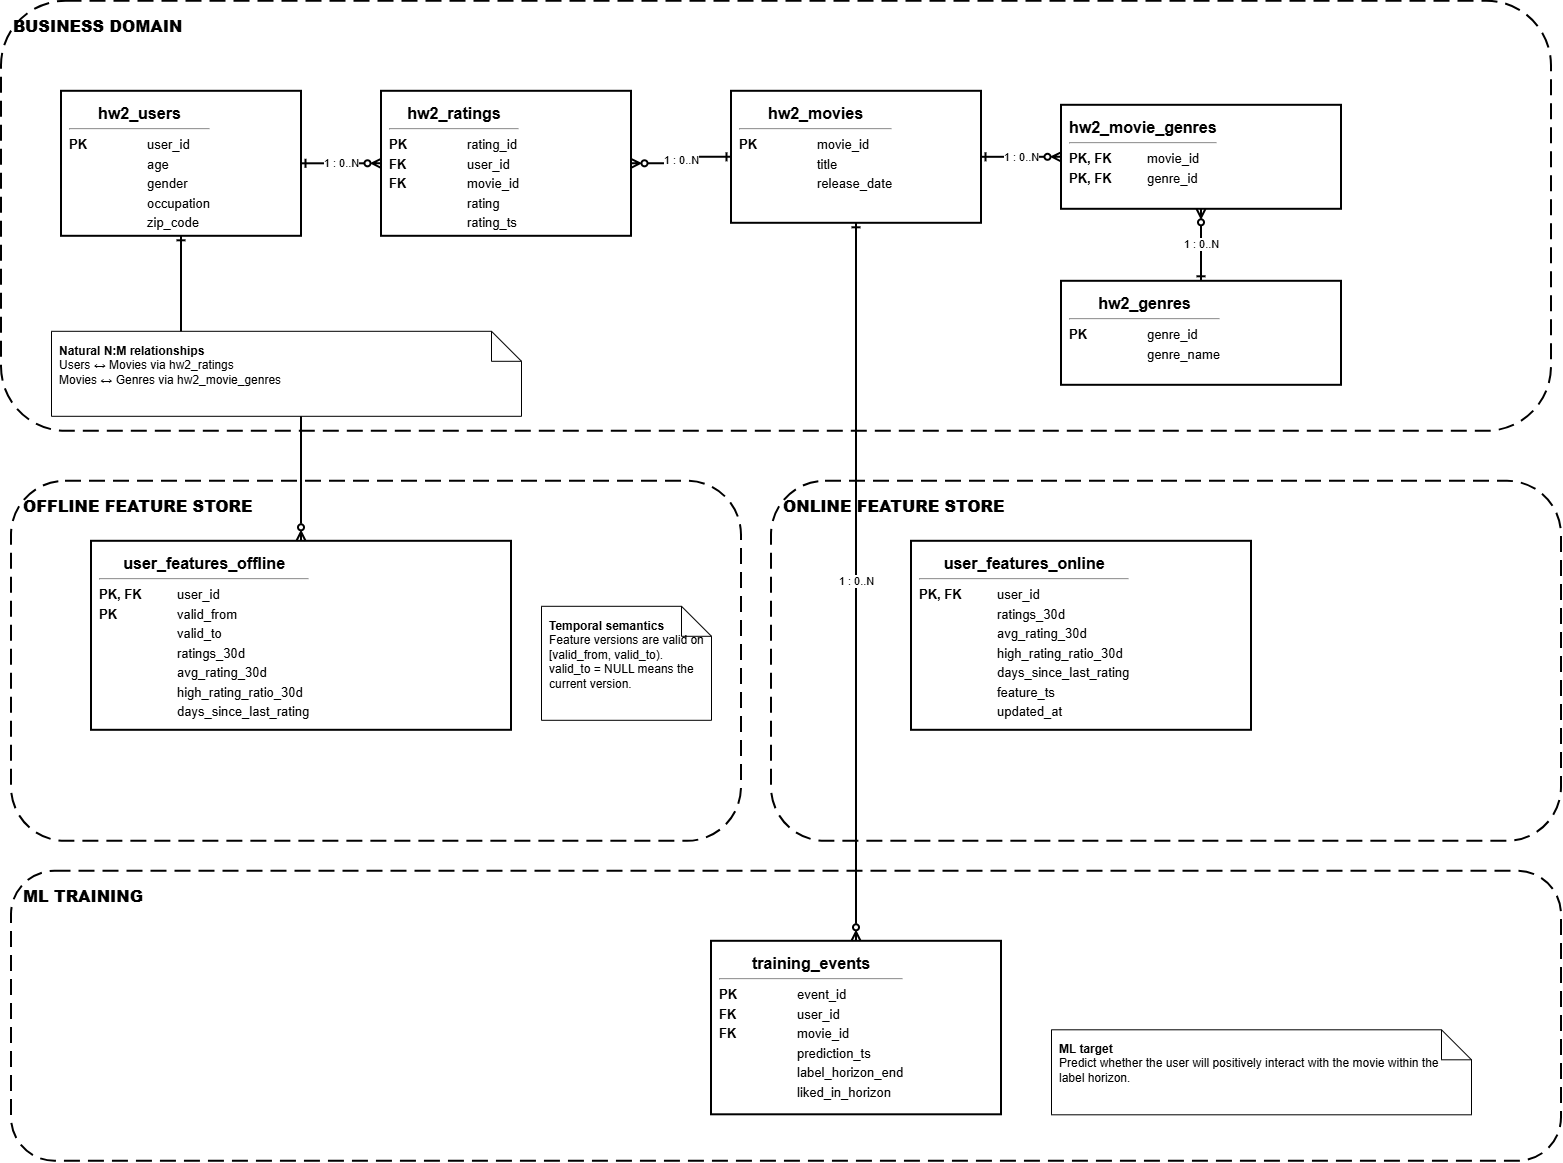

## Завдання 2. DDL у PostgreSQL

In [1]:
# Install PostgreSQL server package for Colab
!pip install -q pgserver==0.1.4 --python-version 3.12 --only-binary=:all: --target=/usr/local/lib/python3.13/dist-packages

# Install Python packages for database access
!pip install -q sqlalchemy psycopg2-binary pandas

import pgserver
from sqlalchemy import create_engine, text

# Start PostgreSQL server
pg = pgserver.get_server('/tmp/pg_data')

# Create SQLAlchemy connection engine
engine = create_engine(pg.get_uri())

# Check database connection
with engine.connect() as conn:
    version = conn.execute(text("SELECT version()")).scalar()

print("PostgreSQL server started successfully")
print(version)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 75.2 MB/s eta 0:00:00
PostgreSQL server started successfully
PostgreSQL 16.2 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 10.2.1 20210130 (Red Hat 10.2.1-11), 64-bit


In [2]:
import pandas as pd

df = pd.read_sql("""
SELECT
    current_database() AS db,
    current_user AS usr,
    version() AS pg_version;
""", engine)

df

,db,usr,pg_version
0,postgres,postgres,"PostgreSQL 16.2 on x86_64-pc-linux-gnu, compil..."


In [3]:
with engine.begin() as conn:
    conn.execute(text("""
        SET TIME ZONE 'UTC';

        DROP TABLE IF EXISTS
            hw2_training_events,
            hw2_user_features_online,
            hw2_user_features_offline,
            hw2_movie_genres,
            hw2_ratings,
            hw2_genres,
            hw2_movies,
            hw2_users
        CASCADE;
    """))


In [4]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE TABLE hw2_users (
            user_id BIGINT PRIMARY KEY,

            age INTEGER NOT NULL CHECK (age > 0),

            gender VARCHAR(20) NOT NULL,

            occupation TEXT NOT NULL,

            zip_code VARCHAR(20)
        );

        CREATE TABLE hw2_movies (
            movie_id BIGINT PRIMARY KEY,

            title TEXT NOT NULL,

            release_date DATE
        );

        CREATE TABLE hw2_genres (
            genre_id INTEGER PRIMARY KEY,

            genre_name VARCHAR(100)
              NOT NULL UNIQUE
        );
    """))

print("Base tables created successfully.")

Base tables created successfully.


In [5]:
tables = pd.read_sql("""
    SELECT table_name
    FROM information_schema.tables
    WHERE table_schema = 'public'
      AND LEFT(table_name, 4) = 'hw2_'
    ORDER BY table_name;
""", engine)

tables

,table_name
0,hw2_genres
1,hw2_movies
2,hw2_users


In [6]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE TABLE hw2_ratings (
            rating_id BIGINT
                GENERATED BY DEFAULT AS IDENTITY
                PRIMARY KEY,

            user_id BIGINT NOT NULL
                REFERENCES hw2_users(user_id),

            movie_id BIGINT NOT NULL
                REFERENCES hw2_movies(movie_id),

            rating INTEGER NOT NULL
                CHECK (rating BETWEEN 1 AND 5),

            rating_ts TIMESTAMPTZ NOT NULL
        );
    """))

print("hw2_ratings created successfully.")


hw2_ratings created successfully.


In [7]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE TABLE hw2_movie_genres (
            movie_id BIGINT NOT NULL
                REFERENCES hw2_movies(movie_id),

            genre_id INTEGER NOT NULL
                REFERENCES hw2_genres(genre_id),

            PRIMARY KEY (movie_id, genre_id)
        );
    """))

print("hw2_movie_genres created successfully.")

hw2_movie_genres created successfully.


In [8]:
fk_check = pd.read_sql("""
    SELECT
        tc.table_name,
        kcu.column_name,
        ccu.table_name AS referenced_table,
        ccu.column_name AS referenced_column
    FROM information_schema.table_constraints AS tc
    JOIN information_schema.key_column_usage AS kcu
        ON tc.constraint_name = kcu.constraint_name
       AND tc.table_schema = kcu.table_schema
    JOIN information_schema.constraint_column_usage AS ccu
        ON tc.constraint_name = ccu.constraint_name
       AND tc.table_schema = ccu.table_schema
    WHERE tc.constraint_type = 'FOREIGN KEY'
      AND LEFT(tc.table_name, 4) = 'hw2_'
    ORDER BY tc.table_name, kcu.column_name;
""", engine)

fk_check

,table_name,column_name,referenced_table,referenced_column
0,hw2_movie_genres,genre_id,hw2_genres,genre_id
1,hw2_movie_genres,movie_id,hw2_movies,movie_id
2,hw2_ratings,movie_id,hw2_movies,movie_id
3,hw2_ratings,user_id,hw2_users,user_id


In [9]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE TABLE hw2_user_features_offline (
            user_id BIGINT NOT NULL
                REFERENCES hw2_users(user_id),

            valid_from TIMESTAMPTZ NOT NULL,
            valid_to TIMESTAMPTZ,

            ratings_30d INTEGER NOT NULL
                CHECK (ratings_30d >= 0),

            avg_rating_30d NUMERIC(3,2)
                CHECK (
                    avg_rating_30d IS NULL
                    OR avg_rating_30d BETWEEN 0 AND 5
                ),

            high_rating_ratio_30d NUMERIC(5,4)
                CHECK (
                    high_rating_ratio_30d IS NULL
                    OR high_rating_ratio_30d BETWEEN 0 AND 1
                ),

            days_since_last_rating INTEGER
                CHECK (
                    days_since_last_rating IS NULL
                    OR days_since_last_rating >= 0
                ),

            PRIMARY KEY (user_id, valid_from),

            CHECK (
                valid_to IS NULL
                OR valid_to > valid_from
            )
        );
    """))

print("hw2_user_features_offline created successfully.")

hw2_user_features_offline created successfully.


In [10]:
with engine.begin() as conn:
    conn.execute(text("""

CREATE INDEX hw2_idx_user_features_asof
ON hw2_user_features_offline (user_id, valid_from DESC);
"""))


In [11]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE TABLE hw2_user_features_online (
            user_id BIGINT PRIMARY KEY
                REFERENCES hw2_users(user_id),

            ratings_30d INTEGER NOT NULL
                CHECK (ratings_30d >= 0),

            avg_rating_30d NUMERIC(3,2)
                CHECK (
                    avg_rating_30d IS NULL
                    OR avg_rating_30d BETWEEN 0 AND 5
                ),

            high_rating_ratio_30d NUMERIC(5,4)
                CHECK (
                    high_rating_ratio_30d IS NULL
                    OR high_rating_ratio_30d BETWEEN 0 AND 1
                ),

            days_since_last_rating INTEGER
                CHECK (
                    days_since_last_rating IS NULL
                    OR days_since_last_rating >= 0
                ),

            feature_ts TIMESTAMPTZ NOT NULL,

            updated_at TIMESTAMPTZ
                NOT NULL DEFAULT CURRENT_TIMESTAMP
        );
    """))

print("hw2_user_features_online created successfully.")

hw2_user_features_online created successfully.


In [12]:
with engine.begin() as conn:
    conn.execute(text("""
        CREATE TABLE hw2_training_events (
            event_id BIGINT
                GENERATED BY DEFAULT AS IDENTITY
                PRIMARY KEY,

            user_id BIGINT NOT NULL
                REFERENCES hw2_users(user_id),

            movie_id BIGINT NOT NULL
                REFERENCES hw2_movies(movie_id),

            prediction_ts TIMESTAMPTZ NOT NULL,

            label_horizon_end TIMESTAMPTZ NOT NULL,

            liked_in_horizon BOOLEAN NOT NULL,

            CHECK (
                label_horizon_end > prediction_ts
            )
        );
    """))

print("hw2_training_events created successfully.")

hw2_training_events created successfully.


In [13]:
fk_check = pd.read_sql("""
    SELECT
        tc.table_name,
        kcu.column_name,
        ccu.table_name AS referenced_table,
        ccu.column_name AS referenced_column
    FROM information_schema.table_constraints AS tc
    JOIN information_schema.key_column_usage AS kcu
        ON tc.constraint_name = kcu.constraint_name
       AND tc.table_schema = kcu.table_schema
    JOIN information_schema.constraint_column_usage AS ccu
        ON tc.constraint_name = ccu.constraint_name
       AND tc.table_schema = ccu.table_schema
    WHERE tc.constraint_type = 'FOREIGN KEY'
      AND LEFT(tc.table_name, 4) = 'hw2_'
    ORDER BY tc.table_name, kcu.column_name;
""", engine)

fk_check

,table_name,column_name,referenced_table,referenced_column
0,hw2_movie_genres,genre_id,hw2_genres,genre_id
1,hw2_movie_genres,movie_id,hw2_movies,movie_id
2,hw2_ratings,movie_id,hw2_movies,movie_id
3,hw2_ratings,user_id,hw2_users,user_id
4,hw2_training_events,movie_id,hw2_movies,movie_id
5,hw2_training_events,user_id,hw2_users,user_id
6,hw2_user_features_offline,user_id,hw2_users,user_id
7,hw2_user_features_online,user_id,hw2_users,user_id


## Завдання 3. Нормалізація
Таблиці, які описують основну бізнес-логіку в цій схемі, побудовані відповідно до третьої нормальної форми (3NF). Наприклад, таблиці `hw2_users`, `hw2_movies` та `hw2_genres` зберігають атрибути, які залежать тільки від їхніх первинних ключів. Таблиця `hw2_ratings` зберігає взаємодії між користувачами та фільмами, а `hw2_movie_genres` використовується для зв’язку «багато-до-багатьох» між фільмами та жанрами.

Основні функціональні залежності такі:
*   `user_id` -> age, gender, occupation, zip_code
*   `movie_id` -> title, release_date
*   `genre_id` -> genre_name
*   `rating_id` -> user_id, movie_id, rating, rating_ts

Такий поділ таблиць допомагає зменшити непотрібне дублювання даних і покращує їхню узгодженість.

Офлайн-таблиця ознак `hw2_user_features_offline` зберігає історичні версії ознак для кожного користувача. Її складений первинний ключ — (`user_id`, `valid_from`), оскільки для одного користувача може бути кілька різних станів ознак у різні моменти часу.

Онлайн-таблиця `hw2_user_features_online` навмисно зроблена денормалізованою. Вона зберігає останній вектор ознак в одному рядку для кожного `user_id`. Такий підхід добре підходить для використання моделі в production, оскільки основний запит — це швидкий пошук даних за `user_id`. Коли всі ознаки зберігаються разом, потрібно виконувати менше JOIN-операцій, що допомагає зменшити затримку.

Недоліком є те, що однакові значення ознак можуть зберігатися і в історичних офлайн-даних, і в онлайн-таблиці. Через це існує ризик, що дані можуть стати неузгодженими. Щоб зменшити цей ризик, онлайн-таблицю варто оновлювати на основі останнього актуального стану з офлайн-сховища ознак.

## Завдання 4. Point-in-Time correctness

In [14]:
with engine.begin() as conn:
    conn.execute(text("""

        -- =========================================================
        -- Users
        -- =========================================================
        INSERT INTO hw2_users
            (user_id, age, gender, occupation, zip_code)
        VALUES
            (1,  25, 'F', 'student',   '79000'),
            (2,  38, 'M', 'engineer',  '79010'),
            (42, 31, 'M', 'scientist', '79020');


        -- =========================================================
        -- Movies
        -- =========================================================
        INSERT INTO hw2_movies
            (movie_id, title, release_date)
        VALUES
            (101, 'The Data Matrix', DATE '2020-05-10'),
            (102, 'SQL Wars',        DATE '2021-08-15'),
            (103, 'Python Story',     DATE '2022-03-20'),
            (104, 'Machine Dreams',   DATE '2023-11-05');


        -- =========================================================
        -- Genres
        -- =========================================================
        INSERT INTO hw2_genres
            (genre_id, genre_name)
        VALUES
            (1, 'Drama'),
            (2, 'Comedy'),
            (3, 'Action');


        -- =========================================================
        -- Movie - Genre bridge
        -- =========================================================
        INSERT INTO hw2_movie_genres
            (movie_id, genre_id)
        VALUES
            (101, 1),
            (102, 2),
            (102, 3),
            (103, 2),
            (104, 1),
            (104, 3);


        -- =========================================================
        -- Ratings / interactions
        -- =========================================================
        INSERT INTO hw2_ratings
            (user_id, movie_id, rating, rating_ts)
        VALUES
            (1, 101, 4, TIMESTAMPTZ '2024-10-10 12:00:00+00'),
            (1, 102, 5, TIMESTAMPTZ '2024-11-20 18:00:00+00'),
            (1, 104, 4, TIMESTAMPTZ '2025-01-05 09:30:00+00'),

            (2, 102, 3, TIMESTAMPTZ '2024-10-25 16:00:00+00'),
            (2, 103, 4, TIMESTAMPTZ '2024-12-05 20:00:00+00'),
            (2, 104, 4, TIMESTAMPTZ '2025-01-03 14:00:00+00'),

            (42, 101, 3, TIMESTAMPTZ '2024-10-15 11:00:00+00'),
            (42, 102, 4, TIMESTAMPTZ '2024-11-12 19:00:00+00'),
            (42, 103, 5, TIMESTAMPTZ '2024-12-18 21:00:00+00'),
            (42, 104, 5, TIMESTAMPTZ '2025-01-18 17:00:00+00');


        -- =========================================================
        -- Offline historical features
        -- 10 temporal records for 3 users
        -- =========================================================
        INSERT INTO hw2_user_features_offline
        (
            user_id,
            valid_from,
            valid_to,
            ratings_30d,
            avg_rating_30d,
            high_rating_ratio_30d,
            days_since_last_rating
        )
        VALUES

            -- User 1: 3 versions
            (
                1,
                TIMESTAMPTZ '2024-10-01 00:00:00+00',
                TIMESTAMPTZ '2024-11-15 00:00:00+00',
                2, 3.50, 0.5000, 5
            ),
            (
                1,
                TIMESTAMPTZ '2024-11-15 00:00:00+00',
                TIMESTAMPTZ '2025-01-01 00:00:00+00',
                4, 4.00, 0.7500, 3
            ),
            (
                1,
                TIMESTAMPTZ '2025-01-01 00:00:00+00',
                NULL,
                7, 4.10, 0.7143, 2
            ),

            -- User 2: 3 versions
            (
                2,
                TIMESTAMPTZ '2024-09-15 00:00:00+00',
                TIMESTAMPTZ '2024-11-01 00:00:00+00',
                1, 3.00, 0.0000, 14
            ),
            (
                2,
                TIMESTAMPTZ '2024-11-01 00:00:00+00',
                TIMESTAMPTZ '2024-12-20 00:00:00+00',
                3, 3.33, 0.3333, 8
            ),
            (
                2,
                TIMESTAMPTZ '2024-12-20 00:00:00+00',
                NULL,
                5, 3.60, 0.4000, 5
            ),

            -- User 42: 4 versions
            (
                42,
                TIMESTAMPTZ '2024-10-01 00:00:00+00',
                TIMESTAMPTZ '2024-11-01 00:00:00+00',
                2, 3.00, 0.0000, 12
            ),
            (
                42,
                TIMESTAMPTZ '2024-11-01 00:00:00+00',
                TIMESTAMPTZ '2024-12-15 00:00:00+00',
                5, 3.60, 0.4000, 6
            ),
            (
                42,
                TIMESTAMPTZ '2024-12-15 00:00:00+00',
                TIMESTAMPTZ '2025-01-15 00:00:00+00',
                8, 4.00, 0.6250, 3
            ),
            (
                42,
                TIMESTAMPTZ '2025-01-15 00:00:00+00',
                NULL,
                12, 4.25, 0.7500, 1
            );


        -- =========================================================
        -- Current online feature snapshot
        -- =========================================================
        INSERT INTO hw2_user_features_online
        (
            user_id,
            ratings_30d,
            avg_rating_30d,
            high_rating_ratio_30d,
            days_since_last_rating,
            feature_ts
        )
        VALUES
            (
                1, 7, 4.10, 0.7143, 2,
                TIMESTAMPTZ '2025-01-20 00:00:00+00'
            ),
            (
            2, 5, 3.60, 0.4000, 5,
                TIMESTAMPTZ '2025-01-20 00:00:00+00'
            ),
            (
                42, 12, 4.25, 0.7500, 1,
                TIMESTAMPTZ '2025-01-20 00:00:00+00'
            );


        -- =========================================================
        -- Training events
        -- =========================================================
        INSERT INTO hw2_training_events
        (
            user_id,
            movie_id,
            prediction_ts,
            label_horizon_end,
            liked_in_horizon
        )
        VALUES
            (
                42,
                102,
                TIMESTAMPTZ '2024-11-20 10:00:00+00',
                TIMESTAMPTZ '2024-11-27 10:00:00+00',
                TRUE
            ),
            (
                42,
                103,
                TIMESTAMPTZ '2024-12-20 10:00:00+00',
                TIMESTAMPTZ '2024-12-27 10:00:00+00',
                TRUE
            ),
            (
                42,
                104,
                TIMESTAMPTZ '2025-01-20 10:00:00+00',
                TIMESTAMPTZ '2025-01-27 10:00:00+00',
                TRUE
            ),
            (
                1,
                103,
                TIMESTAMPTZ '2024-12-10 10:00:00+00',
                TIMESTAMPTZ '2024-12-17 10:00:00+00',
                FALSE
            ),
            (
                2,
                104,
                TIMESTAMPTZ '2025-01-10 10:00:00+00',
                TIMESTAMPTZ '2025-01-17 10:00:00+00',
                TRUE
            );
    """))

print("Test data inserted successfully.")

Test data inserted successfully.


In [15]:
history = pd.read_sql("""
    SELECT
        user_id,
        valid_from,
        valid_to,
        ratings_30d,
        avg_rating_30d
    FROM hw2_user_features_offline
    ORDER BY user_id, valid_from;
""", engine)

history

,user_id,valid_from,valid_to,ratings_30d,avg_rating_30d
0,1,2024-10-01 00:00:00+00:00,2024-11-15 00:00:00+00:00,2,3.50
1,1,2024-11-15 00:00:00+00:00,2025-01-01 00:00:00+00:00,4,4.00
2,1,2025-01-01 00:00:00+00:00,NaT,7,4.10
3,2,2024-09-15 00:00:00+00:00,2024-11-01 00:00:00+00:00,1,3.00
4,2,2024-11-01 00:00:00+00:00,2024-12-20 00:00:00+00:00,3,3.33
5,2,2024-12-20 00:00:00+00:00,NaT,5,3.60
6,42,2024-10-01 00:00:00+00:00,2024-11-01 00:00:00+00:00,2,3.00
7,42,2024-11-01 00:00:00+00:00,2024-12-15 00:00:00+00:00,5,3.60
8,42,2024-12-15 00:00:00+00:00,2025-01-15 00:00:00+00:00,8,4.00
9,42,2025-01-15 00:00:00+00:00,NaT,12,4.25


In [16]:
# 1. AS-OF for user_id = 42 on 2024-11-20

asof_1 = pd.read_sql("""
    SELECT
        user_id,
        ratings_30d,
        avg_rating_30d,
        high_rating_ratio_30d,
        days_since_last_rating,
        valid_from,
        valid_to
    FROM hw2_user_features_offline
    WHERE user_id = 42
      AND valid_from <= TIMESTAMPTZ '2024-11-20 10:00:00+00'
      AND (
            valid_to > TIMESTAMPTZ '2024-11-20 10:00:00+00'
            OR valid_to IS NULL
          );
""", engine)

asof_1

,user_id,ratings_30d,avg_rating_30d,high_rating_ratio_30d,days_since_last_rating,valid_from,valid_to
0,42,5,3.6,0.4,6,2024-11-01 00:00:00+00:00,2024-12-15 00:00:00+00:00


In [17]:
# AS-OF on 2024-12-20
asof_2 = pd.read_sql("""
    SELECT
        user_id,
        ratings_30d,
        avg_rating_30d,
        high_rating_ratio_30d,
        days_since_last_rating,
        valid_from,
        valid_to
    FROM hw2_user_features_offline
    WHERE user_id = 42
      AND valid_from <= TIMESTAMPTZ '2024-12-20 10:00:00+00'
      AND (
            valid_to > TIMESTAMPTZ '2024-12-20 10:00:00+00'
            OR valid_to IS NULL
          );
""", engine)

asof_2

,user_id,ratings_30d,avg_rating_30d,high_rating_ratio_30d,days_since_last_rating,valid_from,valid_to
0,42,8,4.0,0.625,3,2024-12-15 00:00:00+00:00,2025-01-15 00:00:00+00:00


In [18]:
# AS-OF on 2025-01-20
asof_3 = pd.read_sql("""
    SELECT
        user_id,
        ratings_30d,
        avg_rating_30d,
        high_rating_ratio_30d,
        days_since_last_rating,
        valid_from,
        valid_to
    FROM hw2_user_features_offline
    WHERE user_id = 42
      AND valid_from <= TIMESTAMPTZ '2025-01-20 10:00:00+00'
      AND (
            valid_to > TIMESTAMPTZ '2025-01-20 10:00:00+00'
            OR valid_to IS NULL
          );
""", engine)

asof_3

,user_id,ratings_30d,avg_rating_30d,high_rating_ratio_30d,days_since_last_rating,valid_from,valid_to
0,42,12,4.25,0.75,1,2025-01-15 00:00:00+00:00,None


In [19]:
training_data = pd.read_sql("""
    SELECT
        e.event_id,
        e.user_id,
        e.movie_id,
        e.prediction_ts,
        e.label_horizon_end,
        e.liked_in_horizon,

        f.ratings_30d,
        f.avg_rating_30d,
        f.high_rating_ratio_30d,
        f.days_since_last_rating

    FROM hw2_training_events AS e

    LEFT JOIN hw2_user_features_offline AS f
        ON f.user_id = e.user_id
       AND f.valid_from <= e.prediction_ts
       AND (
            f.valid_to > e.prediction_ts
            OR f.valid_to IS NULL
       )

    ORDER BY e.event_id;
""", engine)

training_data

,event_id,user_id,movie_id,prediction_ts,label_horizon_end,liked_in_horizon,ratings_30d,avg_rating_30d,high_rating_ratio_30d,days_since_last_rating
0,1,42,102,2024-11-20 10:00:00+00:00,2024-11-27 10:00:00+00:00,True,5,3.60,0.400,6
1,2,42,103,2024-12-20 10:00:00+00:00,2024-12-27 10:00:00+00:00,True,8,4.00,0.625,3
2,3,42,104,2025-01-20 10:00:00+00:00,2025-01-27 10:00:00+00:00,True,12,4.25,0.750,1
3,4,1,103,2024-12-10 10:00:00+00:00,2024-12-17 10:00:00+00:00,False,4,4.00,0.750,3
4,5,2,104,2025-01-10 10:00:00+00:00,2025-01-17 10:00:00+00:00,True,5,3.60,0.400,5


In [20]:
# Check overlapping intervals
overlaps = pd.read_sql("""
    SELECT
        a.user_id,
        a.valid_from AS a_from,
        a.valid_to   AS a_to,
        b.valid_from AS b_from,
        b.valid_to   AS b_to

    FROM hw2_user_features_offline AS a

    JOIN hw2_user_features_offline AS b
      ON a.user_id = b.user_id
     AND a.valid_from <
         COALESCE(b.valid_to, 'infinity'::timestamptz)
     AND b.valid_from <
         COALESCE(a.valid_to, 'infinity'::timestamptz)
     AND a.valid_from < b.valid_from;
""", engine)

overlaps

,user_id,a_from,a_to,b_from,b_to


Історичні ознаки приєднуються до кожної навчальної події на основі того стану ознак, який був актуальним на момент `prediction_ts`.

Умова `valid_from <= prediction_ts` гарантує, що вибрана версія ознак уже існувала на момент, коли було зроблено прогноз.

Умова верхньої межі `valid_to > prediction_ts OR valid_to IS NULL` гарантує, що вибрана версія ще не була завершена на цей момент. Значення `NULL` у `valid_to` означає, що це поточна активна версія.

Інтервали дії ознак розглядаються як напіввідкриті інтервали: `(valid_from, valid_to)`

Це означає, що `valid_from` входить в інтервал, а `valid_to` — ні. Тому, якщо одна версія ознак закінчується в той самий момент, коли починається наступна, буде вибрана рівно одна версія.

Якщо виконувати JOIN тільки за `user_id`, до кожної навчальної події будуть приєднані всі історичні версії ознак цього користувача. Це призведе до дублювання навчальних рядків, а також може додати значення ознак, які стали доступними лише після `prediction_ts`. Така інформація з майбутнього спричинила б витік даних і могла б дати нереалістично високі результати моделі під час навчання та валідації.

Перевірка перетинів повернула нуль рядків, що підтверджує: для жодного користувача немає перекриття інтервалів дії ознак.

## Завдання 5. Reflection
Це завдання було досить складним, тому що тут потрібно було одночасно поєднати кілька тем: проєктування реляційної схеми, нормалізацію, зберігання історичних ознак, офлайн- та онлайн-сховища ознак, а також формування навчальних даних, правильних з точки зору моменту часу.

Найскладнішою частиною була правильність даних на конкретний момент часу (point-in-time correctness). Потрібно було зрозуміти не тільки, як зберігати кілька історичних версій ознак, але й як вибрати саме ту версію, яка була актуальною на момент `prediction_ts`. Умови з `valid_from` та `valid_to` були особливо важливими, оскільки неправильний JOIN міг би додати інформацію з майбутнього та спричинити витік даних.

Ще однією складною частиною було визначити зв’язки між сутностями та вирішити, де потрібно зберегти нормалізацію, а де буде корисною денормалізація. Бізнес-таблиці залишилися нормалізованими, щоб зменшити дублювання та підтримувати узгодженість даних. Водночас онлайн-таблиця ознак навмисно денормалізована, щоб усі актуальні ознаки користувача можна було отримати одним запитом за `user_id`.

Це створює певний компроміс: однакові значення ознак можуть зберігатися і в офлайн-, і в онлайн-сховищі, тому потрібна їхня синхронізація. Тому онлайн-таблицю варто оновлювати на основі останнього актуального стану ознак з офлайн-сховища.

Якщо б онлайн-пошук потрібно було використовувати для дуже великої кількості користувачів із дуже низькою затримкою, я б залишила один попередньо обчислений рядок ознак для кожного користувача, додала кешування та, за необхідності, використала горизонтальне масштабування.

Протягом наступних шести місяців можливими ризиками при зміні схеми можуть бути перейменування ознак, зміна типів даних, зміна значення або логіки самих ознак, видалення колонок, а також необхідність підтримувати старі версії моделей, які все ще залежать від попередньої версії схеми.